In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam

In [ ]:
# Dataset Access

In [2]:
dataset_path = r"C:\Users\Dell\Downloads\caltech-101\caltech-101\101_ObjectCategories\101_ObjectCategories"

categories = [
    "cougar_body",
    "yin_yang",
    "windsor_chair",
    "wrench",
    "wheelchair"
]

print("Selected Categories:", categories)

Selected Categories: ['cougar_body', 'yin_yang', 'windsor_chair', 'wrench', 'wheelchair']


In [3]:
# Image Preprocessing and Dataset Splitting

In [4]:
datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

# Training dataset
train_data = datagen.flow_from_directory(
    dataset_path,
    classes=categories,
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    subset="training"
)

# Testing dataset
test_data = datagen.flow_from_directory(
    dataset_path,
    classes=categories,
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)

print("Training Images:", train_data.samples)
print("Testing Images:", test_data.samples)
print("Class Labels:", train_data.class_indices)

Found 211 images belonging to 5 classes.
Found 50 images belonging to 5 classes.
Training Images: 211
Testing Images: 50
Class Labels: {'cougar_body': 0, 'yin_yang': 1, 'windsor_chair': 2, 'wrench': 3, 'wheelchair': 4}


In [5]:
# Load Pre-trained VGG16 Model

In [6]:
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

print("VGG16 Model Loaded Successfully!")

VGG16 Model Loaded Successfully!


In [7]:
# Build Custom Classifier

In [8]:
x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(256, activation="relu")(x)

x = Dropout(0.5)(x)

output = Dense(5, activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=output)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 224, 224, 3)   │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block1_conv1 (Conv2D)         │ (None, 224, 224, 64)  │        1,792 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block1_conv2 (Conv2D)         │ (None, 224, 224, 64)  │       36,928 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block1_pool (MaxPooling2D)    │ (None, 112, 112, 64)  │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block2_conv1 (Conv2D)         │ (None, 112, 112, 128) │       73,856 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block2_conv2 (Conv2D)         │ (None, 112, 112, 128) │      147,584 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block2_pool (MaxPooling2D)    │ (None, 56, 56, 128)   │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block3_conv1 (Conv2D)         │ (None, 56, 56, 256)   │      295,168 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block3_conv2 (Conv2D)         │ (None, 56, 56, 256)   │      590,080 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block3_conv3 (Conv2D)         │ (None, 56, 56, 256)   │      590,080 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block3_pool (MaxPooling2D)    │ (None, 28, 28, 256)   │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block4_conv1 (Conv2D)         │ (None, 28, 28, 512)   │    1,180,160 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block4_conv2 (Conv2D)         │ (None, 28, 28, 512)   │    2,359,808 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block4_conv3 (Conv2D)         │ (None, 28, 28, 512)   │    2,359,808 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block4_pool (MaxPooling2D)    │ (None, 14, 14, 512)   │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block5_conv1 (Conv2D)         │ (None, 14, 14, 512)   │    2,359,808 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block5_conv2 (Conv2D)         │ (None, 14, 14, 512)   │    2,359,808 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block5_conv3 (Conv2D)         │ (None, 14, 14, 512)   │    2,359,808 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ block5_pool (MaxPooling2D)    │ (None, 7, 7, 512)     │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ global_average_pooling2d      │ (None, 512)           │            0 │
│ (GlobalAveragePooling2D)      │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense (Dense)                 │ (None, 256)           │      131,328 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dropout (Dropout)             │ (None, 256)           │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_1 (Dense)               │ (None, 5)             │        1,285 │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 14,847,301 (56.64 MB)

 Trainable params: 132,613 (518.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [9]:
# Model Compilation

In [10]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
# Model Training

In [12]:
history = model.fit(
    train_data,
    epochs=5,
    validation_data=test_data
)

Epoch 1/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 103s 7s/step - accuracy: 0.6256 - loss: 3.3253 - val_accuracy: 0.9600 - val_loss: 0.0615
Epoch 2/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 91s 7s/step - accuracy: 0.9763 - loss: 0.1479 - val_accuracy: 0.9600 - val_loss: 0.2113
Epoch 3/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 142s 7s/step - accuracy: 0.9573 - loss: 0.3223 - val_accuracy: 1.0000 - val_loss: 0.0193
Epoch 4/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 141s 7s/step - accuracy: 0.9858 - loss: 0.1170 - val_accuracy: 0.9800 - val_loss: 0.0389
Epoch 5/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 91s 7s/step - accuracy: 0.9905 - loss: 0.0899 - val_accuracy: 0.9800 - val_loss: 0.0355


In [ ]:
# Model Evaluation – Test Accuracy

In [ ]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

In [ ]:
# Predict Five Test Images

In [ ]:
# Get five test images
images, actual_labels = next(test_data)

# Predict images
predictions = model.predict(images[:5])

predicted_labels = np.argmax(predictions, axis=1)
actual_labels = np.argmax(actual_labels[:5], axis=1)

# Display predictions
plt.figure(figsize=(15, 6))

for i in range(5):
    plt.subplot(1, 5, i + 1)

    # Reverse VGG16 preprocessing for display
    img = images[i].copy()
    img = img + [103.939, 116.779, 123.68]
    img = np.clip(img, 0, 255).astype("uint8")
    img = img[:, :, ::-1]

    plt.imshow(img)

    predicted = categories[predicted_labels[i]]
    actual = categories[actual_labels[i]]

    plt.title(f"Predicted: {predicted}\nActual: {actual}")
    plt.axis("off")

    print("Predicted:", predicted)
    print("Actual:", actual)
    print("----------------------")

plt.tight_layout()
plt.show()

In [ ]:
# Training and Validation Accuracy Graph

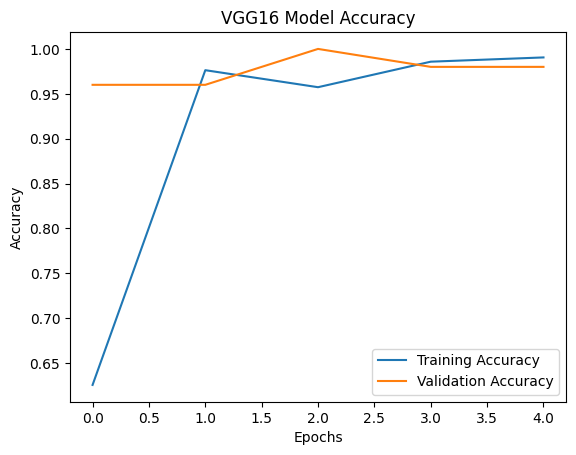

In [13]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("VGG16 Model Accuracy")

plt.legend()
plt.show()